### Memory for agent so that it can remember previous conversion or calcaution in langgprah

In [ ]:
memory = InMemorySaver()

# STEP 4: Create agent with memory
agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a helpful AI assistant. "
        "Use Tavily for news and Wikipedia for general knowledge. "
        "For calculations, always use arithmetic tools. "
        "For follow-up calculations, refer to previous "
        "conversation results. "
        "Your final response MUST answer all parts."
    ),
    checkpointer=memory
)

# STEP 5: Define conversation thread
config = {
    "configurable": {
        "thread_id": "conversation_1"
    }
}

# STEP 6: First question
result1 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Add 30 + 54"}
        ]
    },
    config=config
)

print(result1["messages"][-1].content)

# STEP 7: Follow-up question
result2 = agent.invoke(
    {
        "messages": [
            {"role": "user", "content": "Then add 100 in that number"}
        ]
    },
    config=config
)

print(result2["messages"][-1].content)

# This is using memeroy so that agent can understand the context

NameError: name 'InMemorySaver' is not defined

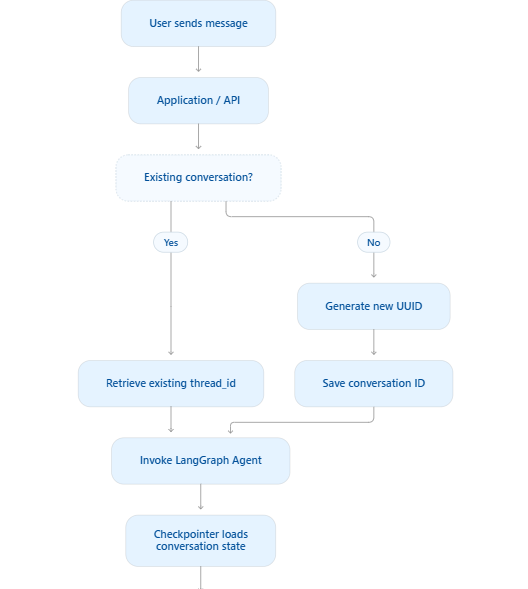

Does config itself store the conversation?
No. This is the most important distinction.
Component	Responsibility
config	Passes execution settings to LangGraph
thread_id	Identifies the conversation
InMemorySaver	Stores and retrieves checkpoints
agent.invoke()	Runs the agent using the selected conversation state
agent.get_state()	Retrieves the latest saved state
In simple terms:
thread_id is like a key, InMemorySaver is the storage system, and config tells LangGraph which key to use.
One important detail: thread_id is a conversation identifier, not necessarily a user identifier. A single user can have multiple independent threads.

No. thread_id in LangGraph is not an actual operating system thread or Python execution thread.
It is simply a unique identifier for a conversation.
For example:
config = {    "configurable": {        "thread_id": "conversation_123"    }}



Here, "conversation_123" is just a string that LangGraph uses to identify and retrieve saved conversation state.

Think of a LangGraph thread as a ChatGPT conversation. Each chat has an identifier so that its history can be retrieved when you send another message.
So:
- thread_id = "123" → Conversation A
- thread_id = "456" → Conversation B
- Reusing "123" → Continue Conversation A

In [ ]:

# Example using Fast API we can also create delte endpoin to delete the chekpoint
#    memory.delete_thread(conversation_id)

import uuid

from fastapi import FastAPI
from pydantic import BaseModel
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage

app = FastAPI()

# Initialize memory once
memory = InMemorySaver()

# Create agent once
agent = create_agent(
    model=llm_groq_agent,
    tools=tools_agent,
    system_prompt=(
        "You are a helpful AI assistant. "
        "Use arithmetic tools for calculations. "
        "Remember previous conversation results."
    ),
    checkpointer=memory
)

# Request model
class ChatRequest(BaseModel):
    message: str
    conversation_id: str | None = None


# API endpoint
@app.post("/chat")
def chat(request: ChatRequest):

    # New conversation -> generate ID
    conversation_id = (
        request.conversation_id or str(uuid.uuid4())
    )

    # Configure memory for this conversation
    config = {
        "configurable": {
            "thread_id": conversation_id
        }
    }

    # Invoke agent
    result = agent.invoke(
        {
            "messages": [
                HumanMessage(content=request.message)
            ]
        },
        config=config
    )

    return {
        "conversation_id": conversation_id,
        "response": result["messages"][-1].content
    }


How should you implement this in LangGraph?
For your FastAPI project, I'd recommend four layers:
- PostgreSQL checkpointer: Persist conversation state rather than keeping it only in RAM.
- Conversation database: Store user IDs, conversation IDs, timestamps, and ownership.
- Context management: Trim or summarize older messages when the conversation becomes too long.
- Retention policy: Delete expired or user-deleted conversations according to your application's requirements